# Declaring Hyperparametrs

In [432]:
CYCLE_COUNT = 0 # No Of Strain Cycle
HIGH = 0 # High Value in a cycle
LOW = 99999 # Low Value in a Cycle
CAL_MOVEMENT = 0 # Net difference between high and low in calibration
Q = 0.50 # Sensitivity of cycle while growing
Q1 = 0.50 # Sensitivity of cycle while falling
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
CALIBRATION_CYCLE_COUNT = 5
def movement():
    return HIGH - LOW

# Defining Imports

In [433]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Getting dataset Ready

In [434]:
colnames = ['reading']
data = pd.read_csv('calibrate.csv',names=colnames)
data.head()
data_actual = pd.read_csv('detect.csv',names=colnames)
data.head()

,reading
0,3689.47
1,3689.84
2,3726.36
3,3753.46
4,3797.94


In [435]:
for i in range(0,CALIBRATION_CYCLE_COUNT):
    print("Give calibration cycle no : ", i+1)
    for val in data['reading']:
        if val >= HIGH:
            HIGH = val
        elif val <= LOW:
            LOW = val
    print(HIGH, LOW)
    CAL_MOVEMENT += movement()
CAL_MOVEMENT /= CALIBRATION_CYCLE_COUNT
GAIN_CHANGE = Q * CAL_MOVEMENT # change after which cycle will be valid
LOSS_CHANGE = Q1 * CAL_MOVEMENT # change for which a cycle will continue
print(" New Calibration Movement is : ", CAL_MOVEMENT)
print(" Gain Change is : ", GAIN_CHANGE)
print(" Loss Change is : ", LOSS_CHANGE)

Give calibration cycle no :  1
4829.4 3689.47
Give calibration cycle no :  2
4829.4 3689.47
Give calibration cycle no :  3
4829.4 3689.47
Give calibration cycle no :  4
4829.4 3689.47
Give calibration cycle no :  5
4829.4 3689.47
 New Calibration Movement is :  1139.9299999999998
 Gain Change is :  569.9649999999999
 Loss Change is :  569.9649999999999


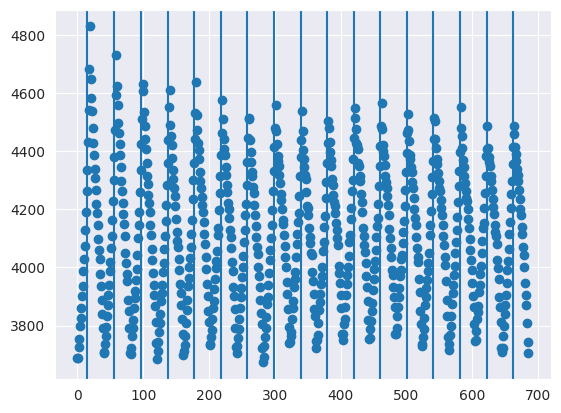

In [436]:
plt.scatter(np.arange(0, data_actual.shape[0], 1, dtype=int), data_actual)
plt.axvline(15, 0, 1, label='pyplot vertical line')
plt.axvline(56, 0, 1, label='pyplot vertical line')
plt.axvline(97, 0, 1, label='pyplot vertical line')
plt.axvline(137, 0, 1, label='pyplot vertical line')
plt.axvline(177, 0, 1, label='pyplot vertical line')
plt.axvline(218, 0, 1, label='pyplot vertical line')
plt.axvline(258, 0, 1, label='pyplot vertical line')
plt.axvline(298, 0, 1, label='pyplot vertical line')
plt.axvline(339, 0, 1, label='pyplot vertical line')
plt.axvline(379, 0, 1, label='pyplot vertical line')
plt.axvline(420, 0, 1, label='pyplot vertical line')
plt.axvline(460, 0, 1, label='pyplot vertical line')
plt.axvline(501, 0, 1, label='pyplot vertical line')
plt.axvline(540, 0, 1, label='pyplot vertical line')
plt.axvline(581, 0, 1, label='pyplot vertical line')
plt.axvline(622, 0, 1, label='pyplot vertical line')
plt.axvline(661, 0, 1, label='pyplot vertical line')
plt.show()
HIGH = data_actual['reading'][0]
LOW = data_actual['reading'][0]
# 15 56 97 137 177 218 258 298 339 379 420 460 501 540 581 622 661

4264.02
4301.08
4335.91
4282.33
4299.48
4313.67
4283.32
4264.22
4316.47
4294.29
4374.35
4347.56
4392.53
4311.47
4332.3
4385.26
4299.28
NET CYCLES   17


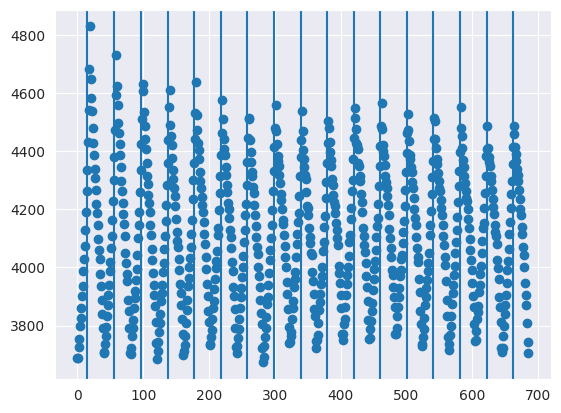

In [437]:
i = 0 # variable to decide which iteration the loop is in
k = 1 # 1 while we apply stain and 0 when we remove strain
count=0
HIGH1 = HIGH
LOW1 = LOW
plt.scatter(np.arange(0, data_actual.shape[0], 1, dtype=int), data_actual)
for val in data_actual['reading']:
    count+=1
    if i==0 and val< LOW1:
        HIGH1 = val
        LOW1  = val
        HIGH = LOW1
        LOW  = HIGH1
        i+=1
        # print("initial high and low value ", HIGH1, LOW1)
    else:
        if i==0:
            HIGH = LOW1
            LOW  = HIGH1
            i+=1
        if val >= HIGH:
            HIGH = val
            # print("high value changed ", HIGH)
            if k==0:
                LOW = HIGH
                LOW1 = LOW
                HIGH1 = HIGH
        if val <= LOW:
            LOW = val
            # print("low value changed ", LOW)
        MOVEMENT = movement()
        # print("MOVEMENT FOUND : ", MOVEMENT)
        if k==1:
            if MOVEMENT >= GAIN_CHANGE:
                # print(HIGH1, HIGH, LOW1, LOW)
                if HIGH-HIGH1 > LOW-LOW1:
                    CYCLE_COUNT+=1
                    plt.axvline(count, 0, 1, label='pyplot vertical line')
                    print(val)
                    # print("New Cycle Detected ", CYCLE_COUNT)
                    k=0
                    LOW = HIGH
                    HIGH1 = HIGH
                    LOW1 = LOW
                else:
                    HIGH = LOW
        elif k==0:
            if MOVEMENT >= LOSS_CHANGE:
                # print("MOVEMENT IS MORE THAN LOSS CHANGE")
                # print(HIGH1, HIGH, LOW1, LOW)
                if HIGH-HIGH1 < LOW1-LOW:
                    LOW1 = val
                    HIGH1 = val
                    i = 0
                    k = 1
print("NET CYCLES  ", CYCLE_COUNT)
plt.show()